In [6]:
###--------------------------------------------LOAD LIBRARIES
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import copy

In [7]:
nonIF =  sc.read("../../../DLPFC_data/DLPFC_Visium/combined_dataframes/nonIF_c2l_anndata_combined_30samples.h5ad")


In [8]:
# Prepare data

subset = nonIF[nonIF.obs['bayesSpace_harmony_7'].isin([2,3,4,5,6])]   # Excluding WM and meningeal layers

subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)
                                                     2 : 'L4', 
                                                     3 : 'L3', 
                                                     4 : 'L2', 
                                                     5 : 'WM',
                                                     6 : 'L1'})

subset.obs['sample_id'] = subset.obs['sample_id'].astype(str)

df_deconvo = subset.obs[np.isnan(subset.obs['Oligo'])==False]

deconvo = ['Astro',
 'EndoMural',
 'Excit_L2_3',
 'Excit_L3',
 'Excit_L3_4_5',
 'Excit_L4',
 'Excit_L5',
 'Excit_L5_6',
 'Excit_L6',
 'Inhib',
 'Micro',
 'OPC',
 'Oligo']

probs = subset.obs[['Astro', 'EndoMural', 'Micro', 'Oligo', 'OPC', 'Excit_L2_3', 'Excit_L3',
       'Excit_L3_4_5', 'Excit_L4', 'Excit_L5', 'Excit_L5_6', 'Excit_L6',
       'Inhib']]
hot1 = copy.copy(probs)
hot1.iloc[:,:] = 0
for m in range (0,np.shape(probs)[0]):
    hot1.iloc[m,:][probs.T[probs.index[m]].nlargest(3).index]=1

annotated = hot1.merge(subset.obs[['sample_id','bayesSpace_harmony_7']], left_index = True, right_index = True, how = 'inner')
annotated = annotated.groupby(['sample_id', 'bayesSpace_harmony_7']).sum().reset_index().melt(id_vars = ['sample_id', 'bayesSpace_harmony_7'])
annotated.to_csv('../../processed_data/01a-4layers_noendo/02-top3_cells_counts/top3_cells_per_layer_count.csv')

/tmp/slurm_12196649/ipykernel_3533951/3160743516.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)


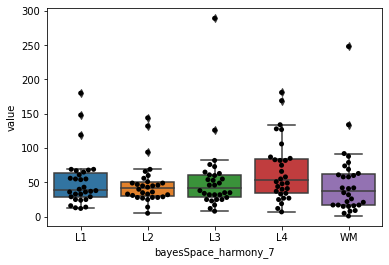

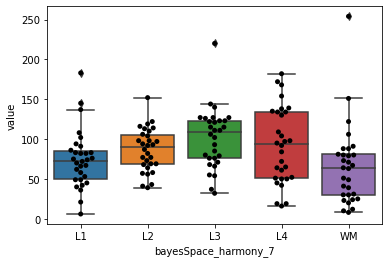

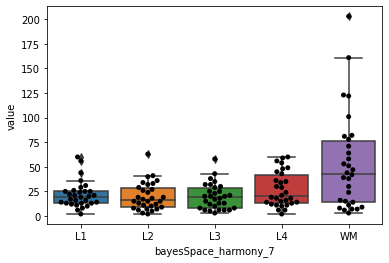

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 46.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


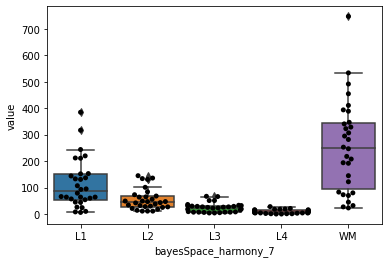

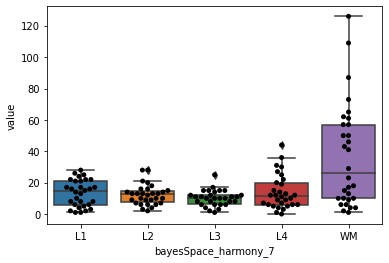

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 36.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


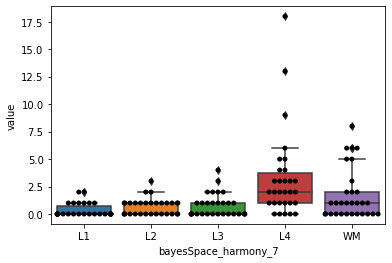

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 56.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


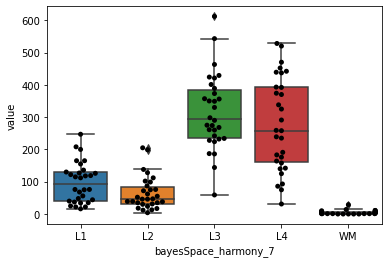

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


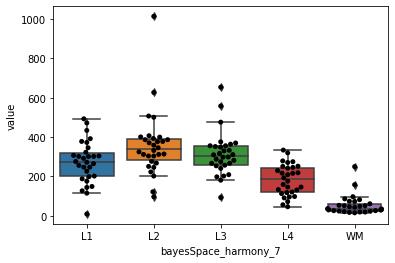

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


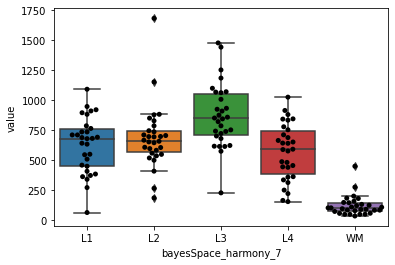

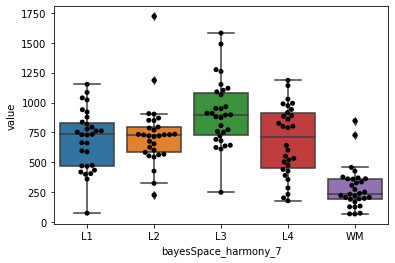

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 60.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


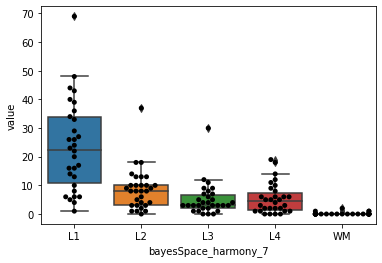

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


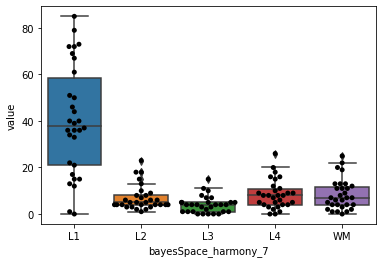

/camp/lab/gandhis/home/users/grantpm/.conda/envs/panpipes/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


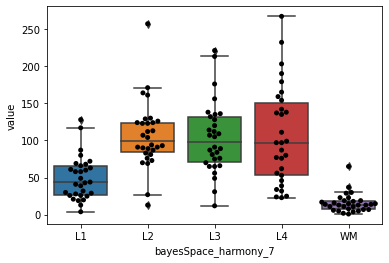

In [9]:
for cell in ['Astro', 'EndoMural', 'Micro', 'Oligo', 'OPC', 'Excit_L2_3', 'Excit_L3',
       'Excit_L3_4_5', 'Excit_L4', 'Excit_L5', 'Excit_L5_6', 'Excit_L6',
       'Inhib']:

    sns.boxplot(data = annotated[annotated['variable']==cell], x = 'bayesSpace_harmony_7', y = 'value')
    sns.swarmplot(data = annotated[annotated['variable']==cell], x = 'bayesSpace_harmony_7', y = 'value', color = 'black')
    plt.savefig('../../plots/01a-4layers_noendo/02-top3_cells_counts/top3_counts_%s.png' % cell)
    plt.show()